## 01: Exploratory Data Analysis 
### 1. Data Overview

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Kaggle-e run korle ei path bodlano lagbe
DATA_PATH = "../data/titanic_data.csv"
# Kaggle: "/kaggle/input/datasets/tariqul1/titanic-data/titanic_data.csv"

#### [Load & first look]

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


#### [ Info, summary, duplicates]

In [6]:
df.info()
display(df.describe())
display(df.describe(exclude="number"))
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


Duplicate rows: 0


### 2. Missing Values

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({"missing": missing, "percent": missing_pct})
missing_df[missing_df["missing"] > 0].sort_values("percent", ascending=False)

,missing,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


### [Missing values-er chart]

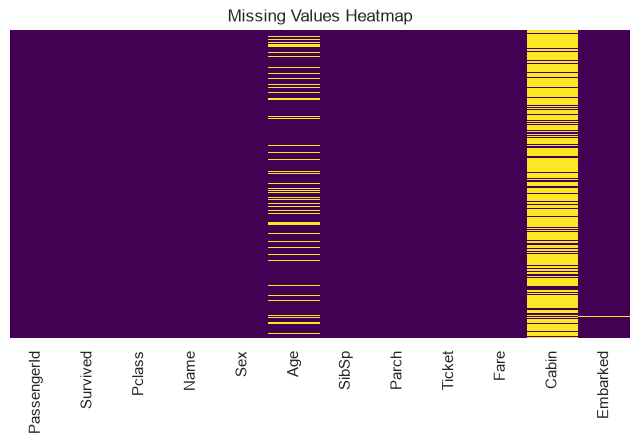

In [5]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values Heatmap")
plt.show()

##### summary = The dataset has 891 passengers and about 38% survived. The main data quality issues are missing values: Cabin is mostly missing, Age is missing for about 20%, and Embarked for just 2 rows. Fare is highly skewed, so I will handle it during preprocessing.

## 3. Target Variable (Survived)

#### [Survived count percentage]

In [7]:
counts = df["Survived"].value_counts().sort_index()
percent = (df["Survived"].value_counts(normalize=True).sort_index() * 100).round(2)

pd.DataFrame({"count": counts, "percent": percent}).rename(
    index={0: "Did not survive", 1: "Survived"}
)

,count,percent
Survived,,
Did not survive,549,61.62
Survived,342,38.38


##### [Count plot]

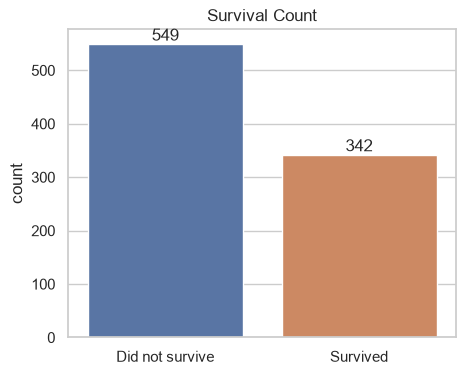

In [8]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Survived", hue="Survived", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive", "Survived"])
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("Survival Count")
plt.xlabel("")
plt.show()

## 4. Univariate Analysis 
### 4a. Numeric Features

#### [Histograms (distribution)]

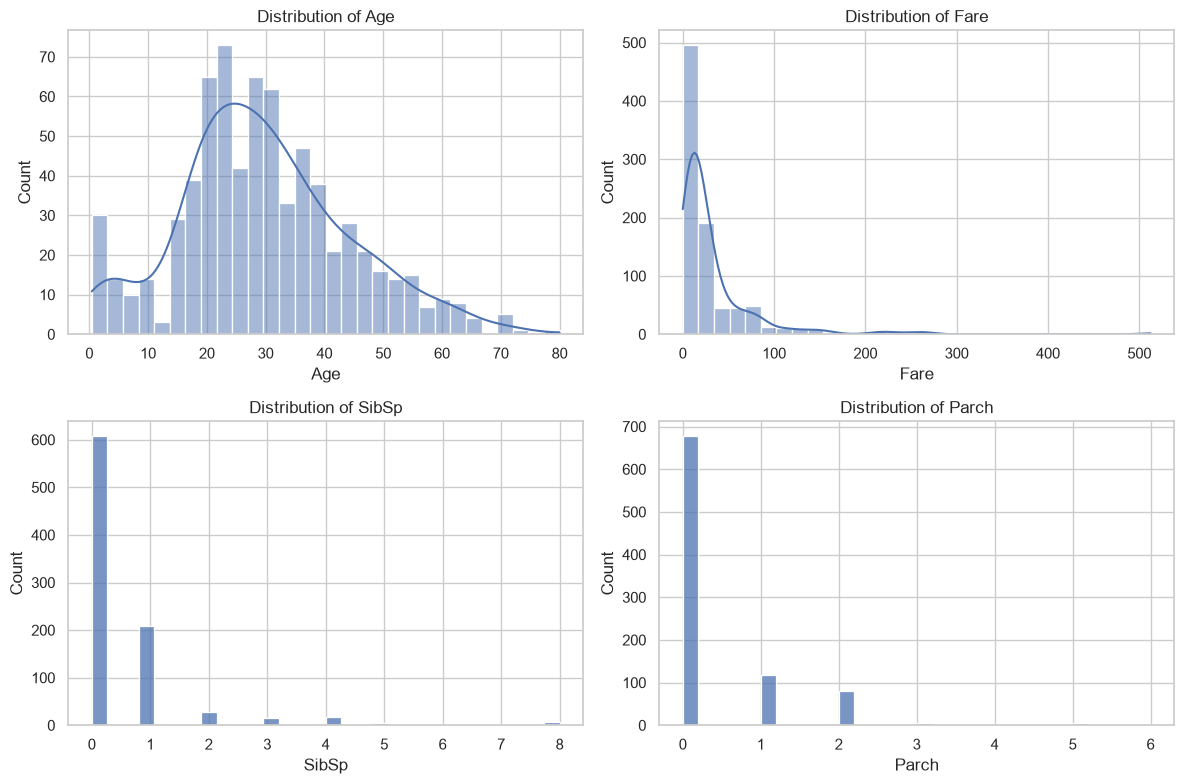

In [9]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(data=df, x=col, kde=(col in ["Age", "Fare"]), bins=30, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

#### [Boxplots (outlier)]

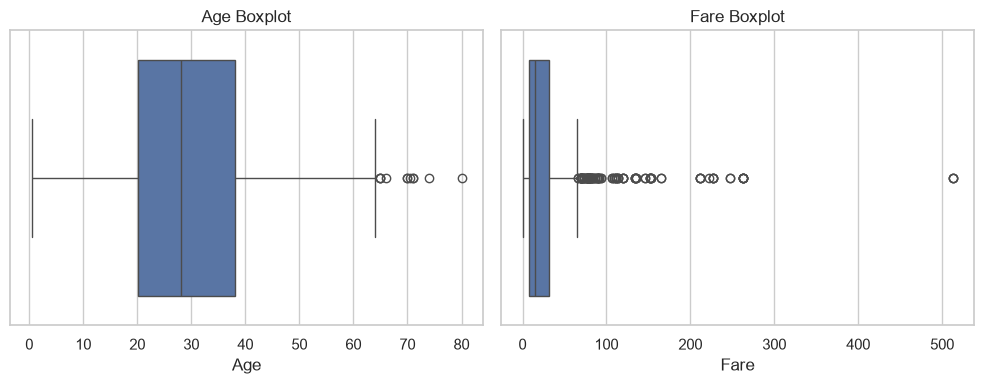

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(data=df, x="Age", ax=axes[0])
axes[0].set_title("Age Boxplot")
sns.boxplot(data=df, x="Fare", ax=axes[1])
axes[1].set_title("Fare Boxplot")
plt.tight_layout()
plt.show()

### Skewness (number diye prove)

In [11]:
df[num_cols].skew().round(2)

Age      0.39
Fare     4.79
SibSp    3.70
Parch    2.75
dtype: float64

### 4b. Categorical Features
#### [Count plots]

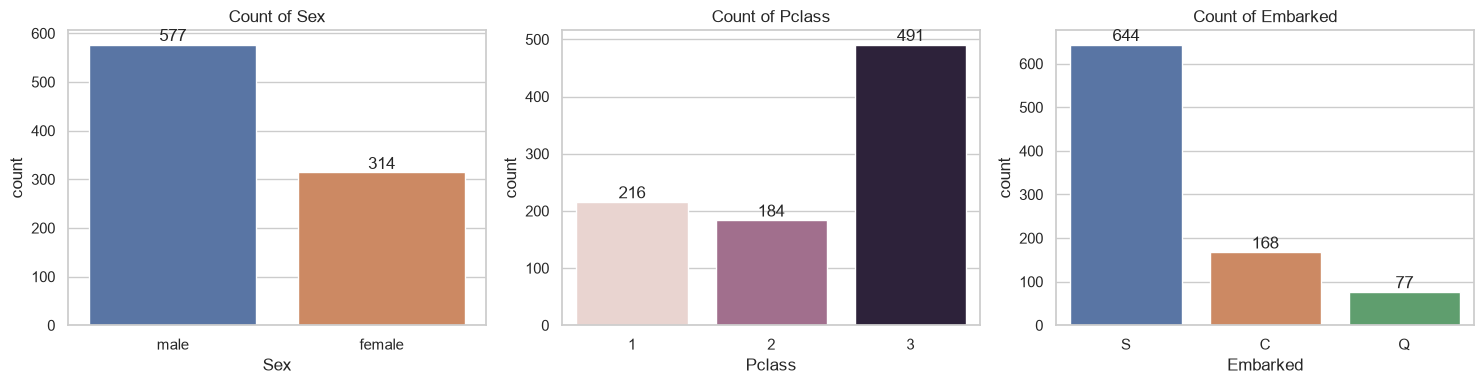

In [12]:
cat_cols = ["Sex", "Pclass", "Embarked"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, cat_cols):
    sns.countplot(data=df, x=col, hue=col, legend=False, ax=ax)
    for container in ax.containers:
        ax.bar_label(container)
    ax.set_title(f"Count of {col}")
plt.tight_layout()
plt.show()